# Risco de acidentes nas rodovias de Santa Catarina — notebook final

**Equipe:** Gustavo Ross · Kevin C. El Azar · Guilherme Assis · Bredley Bauer · Gabriel Coelho · Gustavo Haiduk

Este notebook conta o projeto de ponta a ponta, na ordem do enunciado: problema → dados → exploração →
tratamentos → modelo → avaliação → erros → conclusões → demonstração. Ele **não baixa nada nem retreina**: lê os
artefatos gerados pelos scripts (`backend/scripts/preparar_*.py` e `treinar.py`), ou baixados da Release com
`python -m scripts.baixar_artefatos`, e roda em menos de um minuto.

## 1. Problema e quem usaria

**Pergunta:** *qual a chance de acontecer ao menos um acidente registrado neste trecho de rodovia, neste dia e
neste período do dia (madrugada, manhã, tarde ou noite)?*

| Quem | Para quê |
|---|---|
| Motoristas e transportadoras | escolher horário e rota de viagem; saber quais trechos do caminho pedem mais atenção |
| PRF e DER/SC (polícia e órgão das rodovias estaduais) | decidir **onde e quando** concentrar fiscalização, sinalização e atendimento |
| Defesa Civil, municípios, imprensa | priorizar trechos críticos e comunicar risco em feriados e temporada de verão |

É uma **classificação binária muito desbalanceada** (cerca de 2–3% dos trecho-períodos têm acidente), resolvida
com dois modelos, um por rede de rodovias, porque as fontes de dados são diferentes:

- **BRs (rodovias federais):** acidentes da PRF de 2017–2025; trechos de 10 km pelo km da rodovia;
- **SC-xxx (rodovias estaduais):** acidentes do RENAEST/Senatran de jan/2019–mai/2026; trecho = rodovia dentro
  de um município.

In [1]:
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve

sys.path.insert(0, "backend")  # reaproveita o código do projeto
from app import config

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*encountered in matmul")
pd.set_option("display.max_colwidth", 60)

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({"figure.figsize": (10, 3.8), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11})
NOME_REDE = {"br": "BRs (PRF)", "sc": "Estaduais (RENAEST)"}

A = config.REDES
metricas = {r: json.loads(A[r].metricas.read_text()) for r in A}
acidentes = {r: pd.read_parquet(A[r].acidentes) for r in A}
trechos = {r: pd.read_parquet(A[r].trechos) for r in A}
previsoes = {r: pd.read_parquet(A[r].previsoes_teste) for r in A}
relatorio = json.loads((config.ARTIFACTS / "relatorio_dados.json").read_text())
for r in A:
    m = metricas[r]
    print(f"{NOME_REDE[r]:22s} {len(acidentes[r]):>7,} acidentes | {m['trechos']} trechos | "
          f"dados {m['periodo_dados'][0]} → {m['periodo_dados'][1]} | teste a partir de {m['corte_teste']}")

BRs (PRF)               74,572 acidentes | 249 trechos | dados 2017-01-01 → 2025-12-31 | teste a partir de 2025-01-01
Estaduais (RENAEST)    147,742 acidentes | 443 trechos | dados 2019-01-01 → 2026-05-31 | teste a partir de 2025-06-01


## 2. Dados

| Fonte | O que traz | Uso |
|---|---|---|
| **PRF** — dados abertos, um CSV por ano (2017–2025) | cada acidente nas BRs: data, hora, BR, km, coordenadas, vítimas | alvo e histórico da rede **br** |
| **RENAEST/Senatran** (2019–mai/2026) | todos os acidentes de SC com endereço em texto | alvo e histórico da rede **sc** |
| **OpenStreetMap** (Overpass) | geometria e nomes das rodovias e ruas | trechos, casamento de endereços, mapa |
| **IBGE** | limites dos municípios | trecho estadual = rodovia × município |
| **Open-Meteo** | chuva, nebulosidade e temperatura por hora (grade de 0,25°) | variáveis de clima |
| **DNIT** | volume médio diário de veículos (VMD) por segmento das BRs | variável de tráfego |

Todas as fontes são públicas e baixadas pelos scripts (`README.md` → "Como rodar").

,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
BRs (PRF),10636,8488,8426,7214,7884,7577,7793,8378,8176,0
Estaduais (RENAEST),0,0,16135,17222,20361,20832,21949,17245,23932,10066


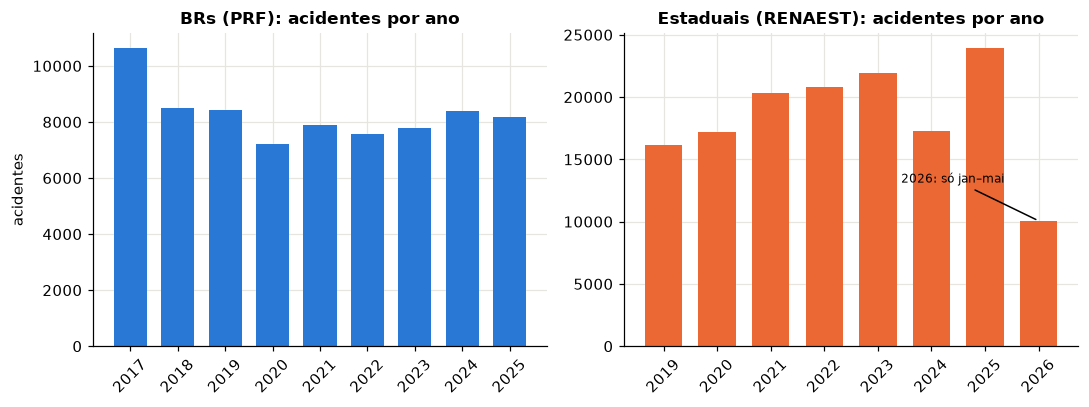

In [2]:
por_ano = pd.DataFrame({NOME_REDE[r]: pd.Series(relatorio[r]["acidentes_por_ano"]) for r in A}).fillna(0).astype(int)
display(por_ano.T)

fig, eixos = plt.subplots(1, 2, sharey=False)
for eixo, r, cor in zip(eixos, A, [AZUL, LARANJA]):
    serie = pd.Series(relatorio[r]["acidentes_por_ano"])
    eixo.bar(serie.index, serie.values, color=cor, width=0.7)
    eixo.set(title=f"{NOME_REDE[r]}: acidentes por ano", ylabel="acidentes" if r == "br" else "")
    eixo.tick_params(axis="x", rotation=45)
eixos[1].annotate("2026: só jan–mai", xy=(len(relatorio["sc"]["acidentes_por_ano"]) - 1, 10066),
                  xytext=(-90, 25), textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "-"})
plt.tight_layout(); plt.show()

**O que isso mostra:** a PRF registra cerca de 8 mil acidentes por ano nas BRs de SC (2017 foi mais alto, 2020
caiu com a pandemia). O RENAEST cresce até 2023, **cai em 2024 e volta a subir em 2025** — essa queda não é menos
acidente, é **menos notificação** (mudança no envio dos registros). Isso virou um tratamento (seção 4).

## 3. Exploração

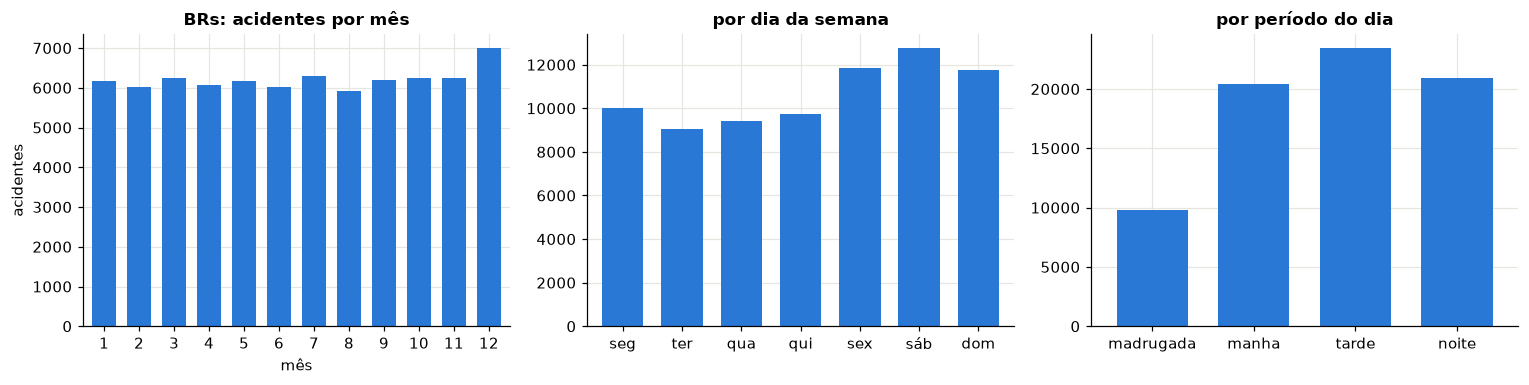

In [3]:
acid_br = acidentes["br"]
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.6))
acid_br.groupby(acid_br["data"].dt.month).size().plot.bar(ax=eixos[0], color=AZUL, width=0.7)
eixos[0].set(title="BRs: acidentes por mês", xlabel="mês", ylabel="acidentes")
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
acid_br.groupby(acid_br["data"].dt.day_of_week).size().rename(dict(enumerate(dias))).plot.bar(
    ax=eixos[1], color=AZUL, width=0.7)
eixos[1].set(title="por dia da semana", xlabel="")
acid_br["periodo"].value_counts().reindex(list(config.PERIODOS)).plot.bar(ax=eixos[2], color=AZUL, width=0.7)
eixos[2].set(title="por período do dia", xlabel="")
for e in eixos:
    e.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

BRs (PRF)              10% dos trechos concentram 49% dos acidentes
Estaduais (RENAEST)    10% dos trechos concentram 65% dos acidentes


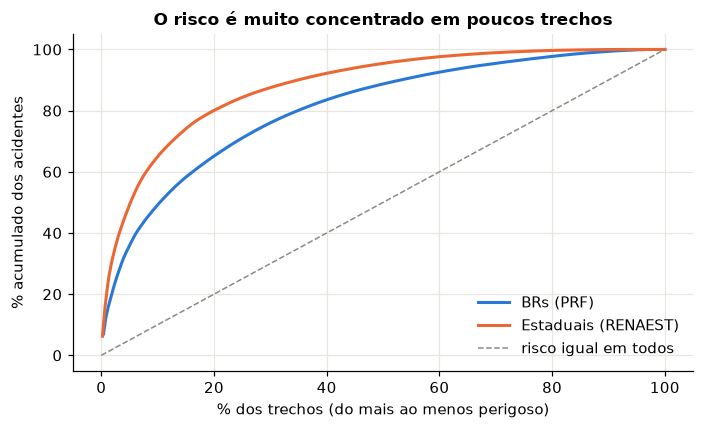

In [4]:
def concentracao(contagem):
    """Parcela dos trechos (do mais ao menos perigoso) × parcela acumulada dos acidentes."""
    c = np.sort(contagem.to_numpy())[::-1]
    return np.arange(1, len(c) + 1) / len(c), np.cumsum(c) / c.sum()

fig, eixo = plt.subplots(figsize=(6.5, 4))
for r, cor in zip(A, [AZUL, LARANJA]):
    x, y = concentracao(trechos[r]["acidentes"])
    eixo.plot(x * 100, y * 100, color=cor, lw=2, label=NOME_REDE[r])
    i10 = int(np.ceil(0.10 * len(x))) - 1
    print(f"{NOME_REDE[r]:22s} 10% dos trechos concentram {y[i10]:.0%} dos acidentes")
eixo.plot([0, 100], [0, 100], color=CINZA, lw=1, ls="--", label="risco igual em todos")
eixo.set(xlabel="% dos trechos (do mais ao menos perigoso)", ylabel="% acumulado dos acidentes",
         title="O risco é muito concentrado em poucos trechos")
eixo.legend(frameon=False); plt.tight_layout(); plt.show()

In [5]:
taxa = {r: previsoes[r]["y"].mean() for r in A}
print("Desbalanceamento do alvo (trecho-períodos com ≥ 1 acidente, no teste):")
for r in A:
    print(f"  {NOME_REDE[r]:22s} {taxa[r]:.2%}  → prever sempre 'sem acidente' acerta {1 - taxa[r]:.1%}")

Desbalanceamento do alvo (trecho-períodos com ≥ 1 acidente, no teste):
  BRs (PRF)              2.10%  → prever sempre 'sem acidente' acerta 97.9%
  Estaduais (RENAEST)    2.92%  → prever sempre 'sem acidente' acerta 97.1%


**O que isso mostra:**

- **Onde** pesa muito mais que **quando**: uma pequena parte dos trechos concentra boa parte dos acidentes
  (curva acima). Mês, dia e período mudam o risco bem menos que a diferença entre trechos.
- Há padrão no tempo: mais acidentes no fim de semana, à tarde, e no fim do ano e no verão.
- O alvo é raro (2–3%): **acurácia não serve** (prever sempre "sem acidente" acerta ~97–98%). Por isso a
  avaliação usa ROC-AUC, PR-AUC, calibração e "captura nos k% de maior risco" (seção 6).

O estudo intermediário `notebooks/estudos/estudo_eda_pca.ipynb` aprofunda a exploração (correlação, VIF, PCA)
com a PRF de 2025.

## 4. Tratamentos dos dados e por quê

| Problema encontrado | Tratamento | Evidência |
|---|---|---|
| O RENAEST tem só o **endereço em texto** ("RUA X, 123") | casar com as vias do OpenStreetMap do mesmo município (por código da rodovia, nome, núcleo do nome, prefixo) | ~90% dos acidentes casados (abaixo) |
| Uma rua com **um** pedaço marcado como SC-xxx no OSM puxava a rua inteira para a rodovia | a rua só herda a rodovia se **≥ 50%** dos seus segmentos são da rodovia (ou se o nome oficial é "Rodovia …") | ruas que seguem estaduais: mediana de 93% dos segmentos com código SC |
| Só existiam trechos **que já tiveram acidente** (viés de seleção) | trechos construídos pela geometria do OSM, com km interpolado; estaduais sem acidente entram com alvo 0 | 26 trechos estaduais sem acidente; nas BRs, 9 anos de dados não deixam nenhum trecho de 10 km sem acidente |
| O histórico do trecho podia **vazar o futuro** | contagens com `shift(1)`: o dia D só vê até D−1; a API usa o mesmo cálculo no fim da base | testes em `backend/tests/test_features.py` |
| Nos primeiros meses a taxa histórica é ruído (poucos dias no denominador) | descartar os 180 primeiros dias do treino | — |
| Clima ausente em algumas células/dias | preencher pela **climatologia** (média da célula × mês × período), não por 0 (0 = "não choveu") | aviso se faltar > 1% |
| A **notificação** do RENAEST varia entre anos (queda em 2024) | variável `nivel_notificacao`: acidentes de SC nos 180 dias anteriores ÷ média do período | gráfico abaixo |
| Pandemia mudou o tráfego (2020–2021) | variável `pandemia` | — |

,parcela
nome,71.1%
codigo,11.1%
sem_casamento,10.3%
nucleo,3.2%
aproximado,3.1%
prefixo,1.1%
vazio,0.0%


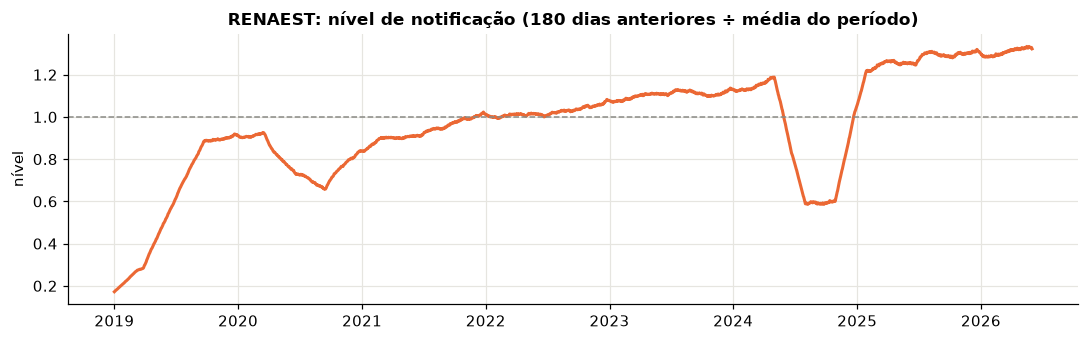

In [6]:
casamento = pd.Series(relatorio["renaest"]["metodo"]).rename("parcela").to_frame()
display(casamento.style.format("{:.1%}"))

notif = pd.read_parquet(A["sc"].notificacao)
fig, eixo = plt.subplots(figsize=(10, 3.2))
eixo.plot(notif["data"], notif["nivel_notificacao"], color=LARANJA, lw=2)
eixo.axhline(1, color=CINZA, lw=1, ls="--")
eixo.set(title="RENAEST: nível de notificação (180 dias anteriores ÷ média do período)", ylabel="nível")
plt.tight_layout(); plt.show()

## 5. Modelo e principais escolhas

- **Unidade de previsão:** trecho × dia × período (4 períodos de 6 h). Alvo = 1 se houve ao menos um acidente.
- **Variáveis:** histórico do trecho (taxa geral, taxa naquele período do dia, acidentes nos últimos 365 dias),
  calendário (dia da semana, mês, feriado, véspera, verão, pandemia), clima (chuva, nebulosidade, temperatura),
  localização (BR/rodovia, lat/lon), VMD (só BRs) e nível de notificação (só estaduais).
- **Algoritmo: `HistGradientBoostingClassifier`** (scikit-learn), um por rede:
  - capta não linearidades e interações (ex.: noite × trecho urbano) que uma regressão logística não capta;
  - aceita valores ausentes e variáveis categóricas sem pré-processamento;
  - restrição **monotônica**: mais acidentes no passado nunca reduzem o risco previsto;
  - rápido em ~3 milhões de linhas.
- **Alternativas testadas** (no estudo intermediário, PRF 2025): regressão logística e PCA. O PCA não ajudou (a
  variância está espalhada em muitos componentes; no boosting, piorou de 0,817 para 0,810 de ROC-AUC) e a
  logística ficou abaixo do boosting (ROC-AUC 0,799 × 0,817).
- **Divisão temporal**, nunca aleatória: treina no passado e testa no último ano (BRs: 2025; estaduais:
  jun/2025–mai/2026). Assim a avaliação imita o uso real — prever um período que o modelo nunca viu.
- **Linhas de base** para saber se o modelo vale a pena: chute aleatório e **"só o histórico do trecho naquele
  período"** (a taxa histórica, sem modelo nenhum).

## 6. Avaliação

In [7]:
linhas = []
for r in A:
    for nome, v in metricas[r]["modelos"].items():
        linhas.append({"rede": NOME_REDE[r], "modelo": nome, **v})
    linhas.append({"rede": NOME_REDE[r], "modelo": "chute_aleatorio", "roc_auc": 0.5,
                   "pr_auc": metricas[r]["taxa_base_teste"]})
tabela = pd.DataFrame(linhas).set_index(["rede", "modelo"])
display(tabela.style.format({"roc_auc": "{:.3f}", "pr_auc": "{:.3f}", "brier": "{:.4f}"}, na_rep="—"))

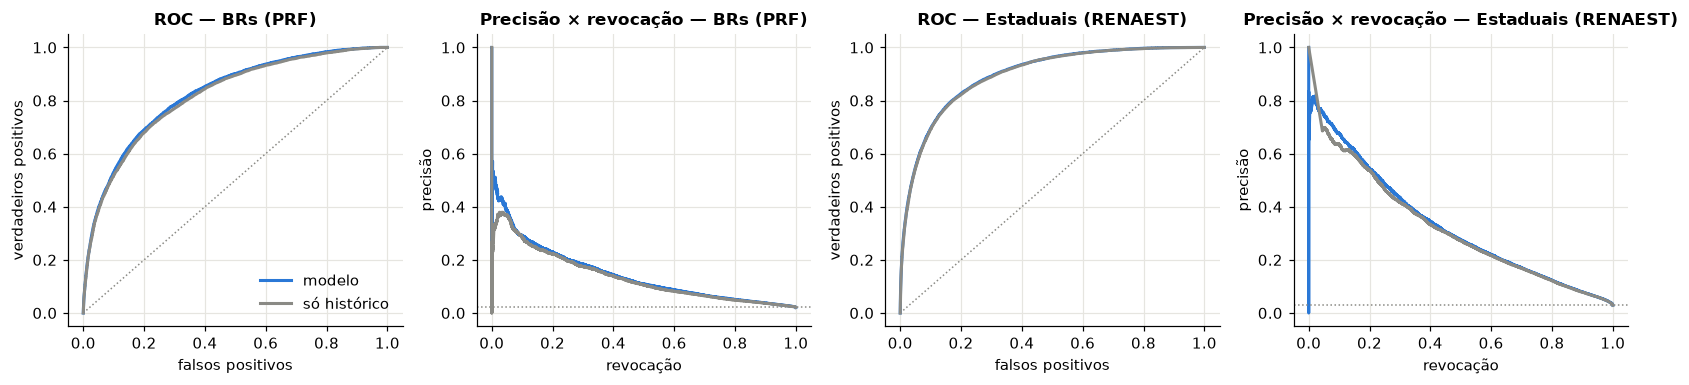

In [8]:
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.6))
for i, r in enumerate(A):
    p = previsoes[r]
    for col, rotulo, cor in [("p_com_clima", "modelo", AZUL), ("p_ingenuo", "só histórico", CINZA)]:
        fpr, tpr, _ = roc_curve(p["y"], p[col])
        eixos[2 * i].plot(fpr, tpr, color=cor, lw=2, label=rotulo)
        prec, rec, _ = precision_recall_curve(p["y"], p[col])
        eixos[2 * i + 1].plot(rec, prec, color=cor, lw=2, label=rotulo)
    eixos[2 * i].plot([0, 1], [0, 1], color=CINZA, lw=1, ls=":")
    eixos[2 * i].set(title=f"ROC — {NOME_REDE[r]}", xlabel="falsos positivos", ylabel="verdadeiros positivos")
    eixos[2 * i + 1].axhline(p["y"].mean(), color=CINZA, lw=1, ls=":")
    eixos[2 * i + 1].set(title=f"Precisão × revocação — {NOME_REDE[r]}", xlabel="revocação", ylabel="precisão")
eixos[0].legend(frameon=False)
plt.tight_layout(); plt.show()

### Uma métrica que qualquer pessoa entende: captura nos k% de maior risco

Se a PRF (ou o DER) só pudesse fiscalizar os **k% de trecho-períodos** que o modelo aponta como mais arriscados,
que parcela dos trecho-períodos que de fato tiveram acidente no ano de teste estaria coberta?

In [9]:
cap = pd.DataFrame({(NOME_REDE[r], fonte): v for r in A for fonte, v in metricas[r]["captura_top_k"].items()}).T
cap.columns = [c.replace("top_", "top ").replace("pct", "%") for c in cap.columns]
display(cap.style.format("{:.0%}"))

### Calibração: quando o modelo diz 5%, acontece em 5% das vezes?

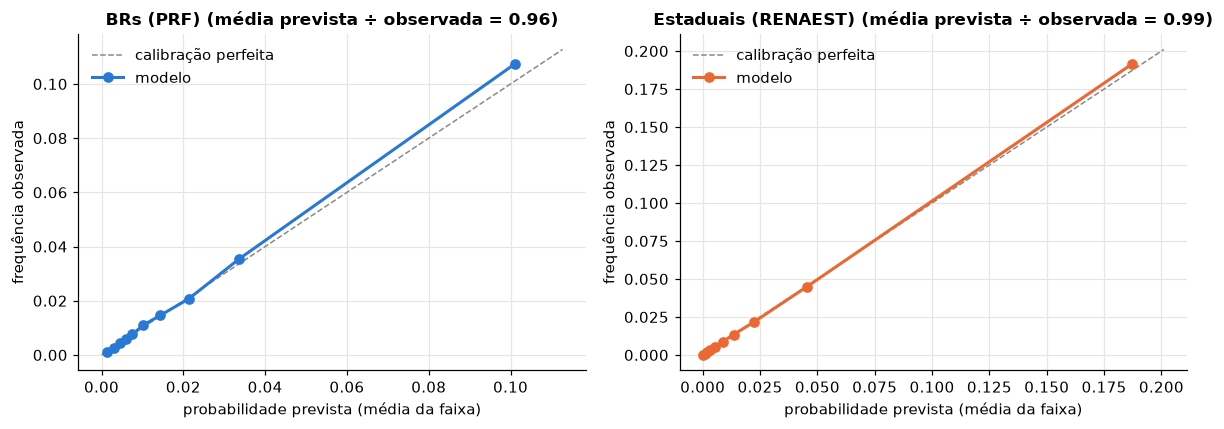

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for eixo, r, cor in zip(eixos, A, [AZUL, LARANJA]):
    cal = pd.DataFrame(metricas[r]["calibracao"]["faixas"])
    lim = max(cal["prob_media"].max(), cal["freq_observada"].max()) * 1.05
    eixo.plot([0, lim], [0, lim], color=CINZA, lw=1, ls="--", label="calibração perfeita")
    eixo.plot(cal["prob_media"], cal["freq_observada"], color=cor, lw=2, marker="o", ms=6, label="modelo")
    razao = metricas[r]["calibracao"]["razao_prevista_observada"]
    eixo.set(title=f"{NOME_REDE[r]} (média prevista ÷ observada = {razao:.2f})",
             xlabel="probabilidade prevista (média da faixa)", ylabel="frequência observada")
    eixo.legend(frameon=False)
plt.tight_layout(); plt.show()

### O clima ajuda em algum caso? E o que mais pesa no modelo?

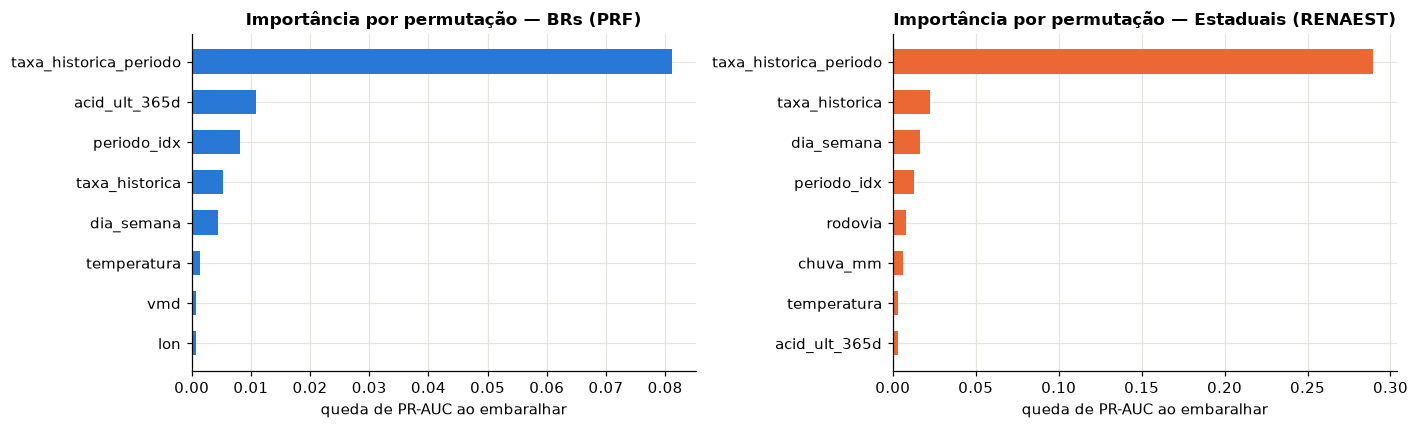

In [11]:
sub = pd.DataFrame({(NOME_REDE[r], k): v for r in A for k, v in metricas[r]["clima_por_subconjunto"].items()}).T
sub["ganho_do_clima"] = sub["pr_auc_com_clima"] - sub["pr_auc_sem_clima"]
display(sub[["linhas", "taxa_base", "pr_auc_com_clima", "pr_auc_sem_clima", "ganho_do_clima"]].style.format(
    {"linhas": "{:,.0f}", "taxa_base": "{:.2%}", "pr_auc_com_clima": "{:.3f}", "pr_auc_sem_clima": "{:.3f}",
     "ganho_do_clima": "{:+.3f}"}))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, r, cor in zip(eixos, A, [AZUL, LARANJA]):
    imp = pd.Series(metricas[r]["importancia"]).head(8).iloc[::-1]
    eixo.barh(imp.index, imp.values, color=cor, height=0.6)
    eixo.set(title=f"Importância por permutação — {NOME_REDE[r]}", xlabel="queda de PR-AUC ao embaralhar")
plt.tight_layout(); plt.show()

### Como as métricas evoluíram a cada tratamento

In [12]:
hist = []
for arq in sorted((config.ARTIFACTS / "historico_metricas").glob("*.json")):
    m = json.loads(arq.read_text())
    v = m["modelos"]["com_clima"]
    hist.append({"etapa": arq.stem, "roc_auc": v["roc_auc"], "pr_auc": v["pr_auc"], "teste": m.get("corte_teste")})
display(pd.DataFrame(hist).set_index("etapa"))

,roc_auc,pr_auc,teste
etapa,,,
00_base_br,0.8167,0.1544,2025-10-01
00_base_sc,0.8747,0.3040,2025-01-01
01_casamento_sc,0.8775,0.3240,2025-01-01
02_renaest2026_notificacao_sc,0.8793,0.3304,2025-06-01
03_historico_sc,0.8775,0.3258,2025-06-01
04_prf2017_br,0.8254,0.1441,2025-01-01
05_trechos_br,0.8254,0.1441,2025-01-01
05_trechos_sc,0.8958,0.3283,2025-06-01
07_vmd_br,0.8254,0.1445,2025-01-01


As etapas não são todas comparáveis entre si: ao incluir a PRF 2017–2025 o período de teste mudou (de out–dez/2025
para o ano de 2025 inteiro), e ao incluir trechos sem acidente o universo de trechos mudou. Por isso cada mudança
foi medida isoladamente antes da seguinte.

## 7. Erros: onde o modelo erra

In [13]:
for r in A:
    e = metricas[r]["erros"]
    print(f"\n{NOME_REDE[r]} — erro absoluto médio por trecho no ano de teste: "
          f"{e['erro_absoluto_medio_por_trecho']} períodos com acidente")
    sub = pd.DataFrame(e["subestimados"]).head(5).assign(tipo="mais acidentes que o previsto")
    sup = pd.DataFrame(e["superestimados"]).head(5).assign(tipo="menos acidentes que o previsto")
    display(pd.concat([sub, sup])[["tipo", "nome", "observados", "esperados"]].set_index("tipo"))


BRs (PRF) — erro absoluto médio por trecho no ano de teste: 4.35 períodos com acidente


,nome,observados,esperados
tipo,,,
mais acidentes que o previsto,BR-280 km 20–30 (ARAQUARI),156,104.7
mais acidentes que o previsto,BR-101 km 200–210 (SAO JOSE),457,422.2
mais acidentes que o previsto,BR-101 km 100–110 (PENHA),112,79.8
mais acidentes que o previsto,BR-101 km 150–160 (PORTO BELO),158,127.1
mais acidentes que o previsto,BR-101 km 0–10 (GARUVA),85,58.2
menos acidentes que o previsto,BR-470 km 70–80 (INDAIAL),28,47.3
menos acidentes que o previsto,BR-470 km 0–10 (NAVEGANTES),69,86.0
menos acidentes que o previsto,BR-101 km 410–420 (ARARANGUA),36,49.7
menos acidentes que o previsto,BR-470 km 170–180 (POUSO REDONDO),21,32.7



Estaduais (RENAEST) — erro absoluto médio por trecho no ano de teste: 6.14 períodos com acidente


,nome,observados,esperados
tipo,,,
mais acidentes que o previsto,SC-412 · Itajaí,329,255.9
mais acidentes que o previsto,SC-281 · São José,272,210.1
mais acidentes que o previsto,SC-108 · Blumenau,571,511.5
mais acidentes que o previsto,SC-447 · Araranguá,217,158.3
mais acidentes que o previsto,SC-108 · Criciúma,699,640.4
menos acidentes que o previsto,SC-437 · Imbituba,76,126.1
menos acidentes que o previsto,SC-480 · Chapecó,183,232.3
menos acidentes que o previsto,SC-418 · Joinville,248,293.6
menos acidentes que o previsto,SC-415 · São Francisco do Sul,212,250.9


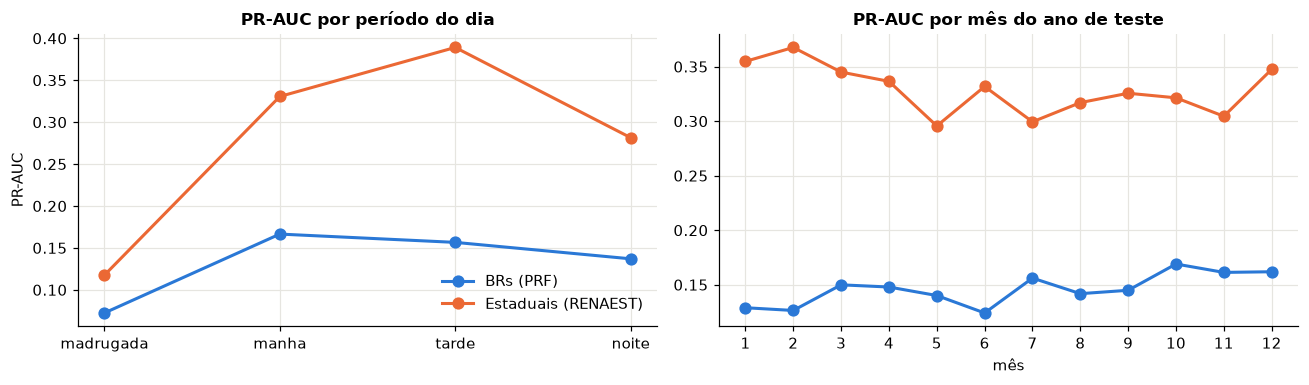

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.6))
for r, cor in zip(A, [AZUL, LARANJA]):
    per = pd.DataFrame(metricas[r]["erros"]["por_periodo"]).T.reindex(list(config.PERIODOS))
    eixos[0].plot(per.index, per["pr_auc"], color=cor, lw=2, marker="o", ms=7, label=NOME_REDE[r])
    mes = pd.DataFrame(metricas[r]["erros"]["por_mes"]).T
    mes.index = mes.index.astype(int)
    mes = mes.sort_index()
    eixos[1].plot(mes.index, mes["pr_auc"], color=cor, lw=2, marker="o", ms=7, label=NOME_REDE[r])
eixos[0].set(title="PR-AUC por período do dia", ylabel="PR-AUC")
eixos[1].set(title="PR-AUC por mês do ano de teste", xlabel="mês", xticks=range(1, 13))
eixos[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Leitura dos erros:**

- Os maiores erros estão nos trechos **mais movimentados** — eles têm mais acidentes, então também têm mais
  variação de um ano para o outro. Quando um trecho muda de patamar (obra, duplicação, novo radar, mudança na
  notificação), o histórico demora a acompanhar e o modelo erra para cima ou para baixo.
- O desempenho varia entre os períodos do dia: a **madrugada** tem poucos acidentes (PR-AUC baixo também porque a
  taxa base é menor) e é mais difícil de ordenar. Entre os meses o desempenho é estável — não há uma época em que o
  modelo "quebre".
- Na calibração, a faixa de maior risco é levemente **subestimada** (prevê ~10%, acontece ~10,7% nas BRs): os
  trechos mais perigosos são um pouco piores do que o modelo diz.
- Na rede estadual, parte do erro vem da **notificação** (um município que passa a registrar mais ou menos) e
  do **casamento de endereços** (um acidente que não foi ligado à rodovia certa), não do trânsito.

## 8. Conclusões

1. **O risco é sobretudo uma questão de *onde*.** O modelo supera todas as linhas de base, mas por pouco o
   "só histórico do trecho naquele período": a maior parte do sinal está no histórico do trecho. Isso não é um
   defeito — é o principal resultado: para decidir **onde** fiscalizar, o histórico já diz muito; o modelo
   acrescenta o **quando** (dia, feriado, período) de forma consistente e calibrada.
2. **Ordenar bem é útil na prática:** os 10% de trecho-períodos de maior risco concentram cerca de metade dos
   acidentes nas BRs (tabela "captura").
3. **As probabilidades são confiáveis** (curva de calibração próxima da diagonal), por isso a interface pode
   mostrar "X% de chance" e comparar com a média do trecho.
4. **Clima e tráfego quase não acrescentam.** Na média do teste a chuva forte aumenta um pouco o risco previsto
   (nas BRs, de 2,0% para 2,4% por trecho-período), mas o efeito muda de trecho para trecho — num trecho urbano
   muito movimentado ela pode até reduzir o risco, porque tira carros da rua (exemplo da seção 10). E o clima não
   melhora a ordenação nem em noites, verão ou dias de chuva. O VMD já está embutido no histórico do trecho.
5. **Para que serve / não serve:** serve para **comparar** trechos, dias e horários e priorizar atenção; não
   serve como garantia de segurança de uma viagem individual, nem para trechos sem registros confiáveis.

## 9. Limitações e trabalhos futuros

- Só acidentes **registrados**: a PRF cobre as BRs; o RENAEST depende do envio de cada órgão e varia no tempo.
- O casamento de endereço do RENAEST erra em parte dos casos; trechos estaduais com zero acidentes podem ser falha
  de casamento, não segurança.
- Rodovias estaduais longas viram um único trecho por município (não há km confiável no RENAEST).
- O clima é de reanálise numa grade de ~25 km, não do local exato do acidente.
- **Futuro:** prever gravidade (vítima grave ou fatal), incluir a PRF de 2026, usar o km escrito no endereço para
  dividir as rodovias estaduais longas.

## 10. Demonstração de uso

Uma nova entrada (rodovia + km ou município, data, período e clima) produz uma probabilidade explicada. É o mesmo
código da API usada pela interface web (`bash rodar.sh` → http://localhost:3000).

In [15]:
sys.path.insert(0, "backend")
import os
os.chdir("backend")
from scripts.prever import main as prever

_ = prever(["--rodovia", "BR-101", "--km", "205", "--data", "2026-12-24", "--periodo", "noite",
            "--clima", "chuva_forte"])


Trecho:   BR-101 · km 200–210 (SAO JOSE) — 582,6 acidentes/ano em média
Cenário:  2026-12-24, noite, clima chuva_forte (véspera/pós-feriado, verão)

Chance de ao menos um acidente neste trecho e período: 35,0%
Média histórica do trecho nesse período do dia:      35,2%  → 0,99× a média

O que mais pesa (comparado com a referência):
   -11%  Chuva forte (vs. céu claro)
   +10%  Período: noite (vs. média do dia)
    -6%  Época do ano (vs. média dos meses)

Aviso: a estimativa vem de acidentes registrados (PRF/RENAEST) e reflete sobretudo o histórico do
trecho; não é uma garantia de segurança nem considera obras, eventos ou o seu modo de dirigir.


In [16]:
_ = prever(["--rodovia", "SC-401", "--municipio", "Florianópolis", "--data", "2027-01-10", "--periodo", "tarde"])
os.chdir("..")


Trecho:   SC-401 · Florianópolis — 1249 acidentes/ano em média
Cenário:  2027-01-10, tarde, clima ceu_claro (fim de semana, verão)

Chance de ao menos um acidente neste trecho e período: 63,1%
Média histórica do trecho nesse período do dia:      69,5%  → 0,91× a média

O que mais pesa (comparado com a referência):
   -16%  Fim de semana (vs. quarta-feira comum)
   +15%  Período: tarde (vs. média do dia)
    +9%  Época do ano (vs. média dos meses)

Aviso: a estimativa vem de acidentes registrados (PRF/RENAEST) e reflete sobretudo o histórico do
trecho; não é uma garantia de segurança nem considera obras, eventos ou o seu modo de dirigir.
